# Discriminability gradients, synthetic neurons → `gradients_ideal.pdf`

**Exactly the analysis of [`gradients.ipynb`](gradients.ipynb)** — same neuron selection, same
trials, same smoothing, same measure, same figure — with one change: each selected neuron's
**firing rates are replaced by an idealized neuron's**. Every trial keeps its recorded stimulus
$(\theta_0, \theta_1)$, so the synthetic populations are sampled exactly as the real ones were:
the 80° edge, the sampling density and every neuron's trial count are the same. What differs
between the two figures is therefore the tuning, and nothing about how it was measured.

The ideal neurons are those of
[`../figure_3/model_comparison/ideal_neurons.ipynb`](../figure_3/model_comparison/ideal_neurons.ipynb):

* retinotopic, $r = b + a\,[\cos(\theta_0-\mu) + \cos(\theta_1-\mu)]$ — one receptive field
  applied to each object;
* relational, $r = b + a\cos(\theta_0+\theta_1-\chi)$ — tuned to the pair's sum.

The retinotopic population's neurons are made retinotopic and the relational population's
relational. Their preferred directions tile the ring evenly, each one's baseline is its recorded
counterpart's mean rate, and each trial's rate is a Poisson draw, so the estimators face
realistic noise (`SYNTH_*` in the config).

This is the reference for reading `gradients.ipynb`: anything that appears here too — at the
stimulus-set edge, for instance — is produced by the sampling and the estimator, not by the
neurons. **Keep the config in step with `gradients.ipynb`** (everything except `OUTPUT` and the
`SYNTH_*` block) or the two figures are no longer the same analysis.


In [1]:
import sys
from pathlib import Path

import numpy as np
from matplotlib import pyplot as plt

# The repository root (where paths.py lives), found from this notebook's folder.
_root = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'paths.py').exists())
sys.path.insert(0, str(_root))
import paths
sys.path.insert(0, str(paths.FIGURES / 'supp_figure_3'))
import common
import gradients_lib as gl

common.set_style()

# ── CONFIG ───────────────────────────────────────────────────────────────────
# The populations: every neuron is assigned to whichever model (retinotopic or relational) fits
# it better, and each population is then the top K of its neurons by fit strength, ranked over
# both animals together (mostly Monkey P, whose fits run stronger).
SUBJECTS = ('Perle', 'Elgar')
K = 20                   # neurons in EACH population
MIN_SEP_DEG = 83.0       # grid points with the objects closer than this are left empty

# ── The measure: linear Fisher information from kernel-weighted means ───────
KERNEL_SIGMA_DEG = 20.0  # Gaussian kernel width on the (theta_0, theta_1) distance
LF_STEP_DEG = 25.0       # distance between the two stimuli compared
N_DIRECTIONS = 6         # directions through each point, evenly over [0°, 180°); at least 3
N_GRID = 12              # the (theta_0, theta_1) grid: N_GRID bins per angle (12 -> 30° cells)

# ── The synthetic firing rates ──────────────────────────────────────────────
# Each selected neuron keeps its recorded STIMULI (every trial's theta_0, theta_1) and gets an
# ideal neuron's rates in place of its own: retinotopic r = b + a[cos(th0 - mu) + cos(th1 - mu)],
# relational r = b + a cos(th0 + th1 - chi), as in ../figure_3/model_comparison/ideal_neurons.ipynb.
# Preferred directions are evenly spaced around the ring, tiling every orientation; the baseline
# is the counterpart's mean recorded rate and the peak-to-trough swing SYNTH_MODULATION x that
# baseline; each trial's count is Poisson(rate x SYNTH_DURATION_S).
SYNTH_MODULATION = 0.5
SYNTH_DURATION_S = 1.0
SYNTH_SEED = 0

# ── Figure ───────────────────────────────────────────────────────────────────
STEP = 1                 # a segment at every STEP-th grid point (1 = every one of the 12 x 12)
FIGSIZE = (3.4, 3.6)
LINE_WIDTH = 1.6
LINE_ALPHA = 0.9
COLORS = {'retinotopic': 'tab:blue', 'relational': 'tab:orange'}
DRAW_ORDER = ('retinotopic', 'relational')     # the last is drawn on top
OUTPUT = 'gradients_ideal.pdf'

## 1. The synthetic populations and their discriminability fields

In [2]:
units = gl.population_units(SUBJECTS, K)
recorded = gl.load_trials(units)
# The only difference from gradients.ipynb: same neurons, same stimuli, ideal rates.
trials = {side: gl.synthetic_trials(t, side, modulation=SYNTH_MODULATION,
                                    duration_s=SYNTH_DURATION_S, seed=SYNTH_SEED + i)
          for i, (side, t) in enumerate(recorded.items())}
mask = gl.sampled_mask(N_GRID, MIN_SEP_DEG)

J, info = gl.linear_fisher_field(trials, gl.plotted_points(mask, STEP),
                                 step_deg=LF_STEP_DEG, n_directions=N_DIRECTIONS,
                                 sigma_deg=KERNEL_SIGMA_DEG)
ne = info['n_eff_min'][np.isfinite(info['n_eff_min'])]
print(f'{len(trials["relational"])} units per population; smallest '
      f'effective trial count of any unit at a point: median {np.median(ne):.1f}, '
      f'min {ne.min():.1f}')

fields = {side: gl.top_direction(j) for side, j in J.items()}
display(gl.summary(fields, mask).round(3))

  retinotopic : 20 of 497 (fit strength 0.312–0.431, median 0.345)
  relational  : 20 of 842 (fit strength 0.374–0.612, median 0.413)
20 units per population; smallest effective trial count of any unit at a point: median 31.6, min 13.4


,n_points,median_abs_cos_rotation,frac_closer_to_rotation,median_dprime_per_rad
population,,,,
retinotopic,84,0.155,0.238,2.188
relational,84,0.999,1.000,2.836


## 2. The figure

`median_abs_cos_rotation` above is $|\cos|$ between each population's best direction and the
rotation axis $(1,1)/\sqrt2$, over every sampled grid stimulus: 1 is pure rotation, 0 pure
separation change, 0.71 halfway.

saved gradients_ideal.pdf


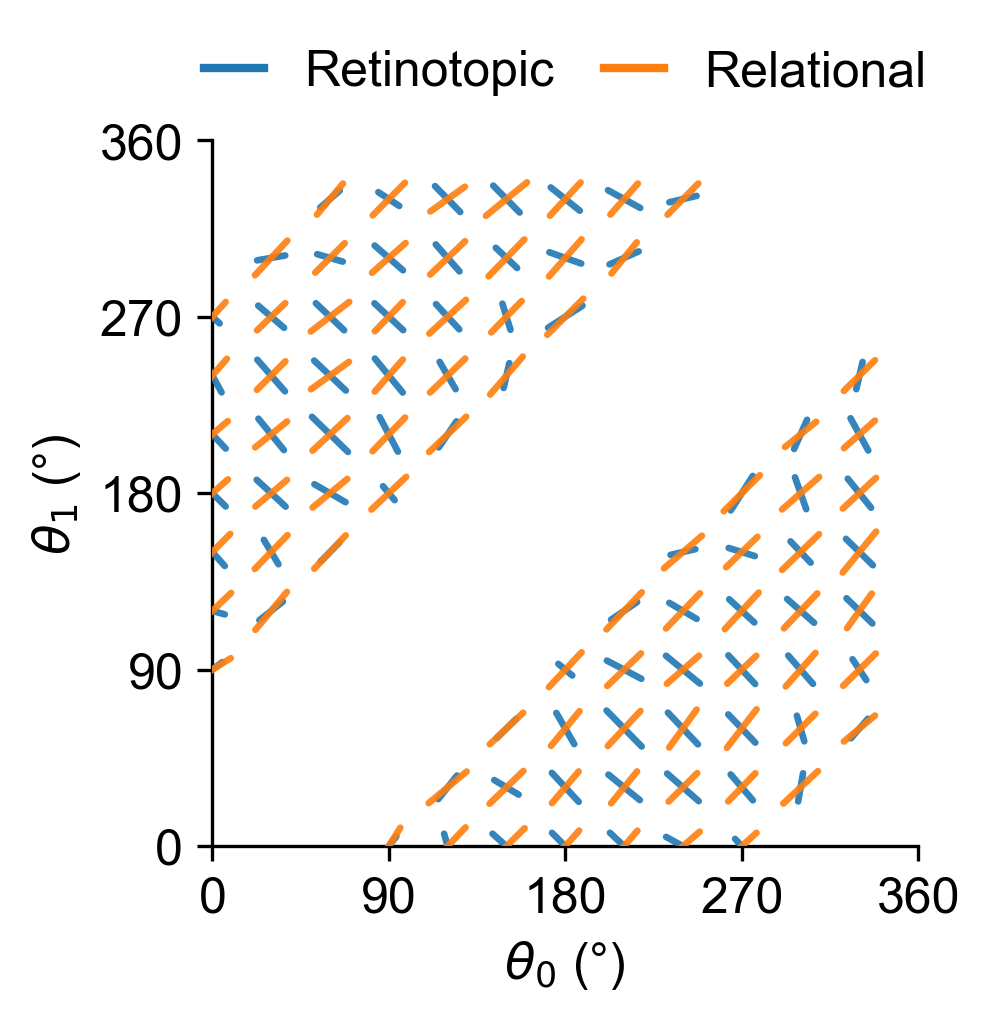

In [3]:
fig, ax = gl.plot_field(fields, mask, STEP, figsize=FIGSIZE, colors=COLORS, lw=LINE_WIDTH,
                        alpha=LINE_ALPHA, order=DRAW_ORDER)
common.save(fig, OUTPUT)
plt.show()